<a href="https://colab.research.google.com/github/leonIceHot/Computer-Vision-Course/blob/main/CH8_%E9%82%8A%E7%B7%A3%E5%81%B5%E6%B8%AC%E8%88%87%E5%BD%B1%E5%83%8F%E6%A2%AF%E5%BA%A6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1.影像微分與梯度概念 (Gradients Basics)

在數位影像處理中，影像微分（Image Differentiation） 與影像梯度（Image Gradient）是邊緣偵測（Edge Detection）、特徵萃取（如 SIFT、HOG）以及影像銳化（Sharpening）的核心數學工具。

---

一、 核心概念：為什麼需要微分？

數位影像可以視為二維離散函數 $f(x, y)$，其中 $(x, y)$ 為空間座標，$f(x, y)$ 代表該位置的像素強度（如灰階值 $0 \sim 255$）。

* **平坦區域（Flat Region）**：鄰近像素值變化極小或為零。
* **邊緣（Edge）**：鄰近像素值在短距離內產生劇烈變化（例如從暗到亮）。

在微積分中，導數（Derivative）表示數值的變化率。因此，**影像微分本質上就是用來衡量像素強度的變化劇烈程度**；強度變化最劇烈的地方，通常就是物體的輪廓或邊緣。

---

二、 離散空間的微分：有限差分 (Finite Difference)

連續函數的一維導數定義為：
$\frac{df}{dx} = \lim_{\Delta x \to 0} \frac{f(x + \Delta x) - f(x)}{\Delta x}$

因為數位影像是離散訊號，最小取樣距離為一個像素（即 $\Delta x = 1$），因此需使用**有限差分**近似：

1. **前向差分（Forward Difference）**：
   $\frac{\partial f}{\partial x} \approx f(x + 1, y) - f(x, y)$

2. **後向差分（Backward Difference）**：
   $\frac{\partial f}{\partial x} \approx f(x, y) - f(x - 1, y)$

3. **中央差分（Central Difference）**（具對稱性，最常用）：
   $\frac{\partial f}{\partial x} \approx \frac{f(x + 1, y) - f(x - 1, y)}{2}$

---

三、 影像梯度 (Image Gradient)

影像有水平（$x$ 軸）與垂直（$y$ 軸）兩個維度。在點 $(x, y)$ 的**梯度向量（Gradient Vector）**定義為：

$\nabla f = \begin{bmatrix} g_x \\ g_y \end{bmatrix} = \begin{bmatrix} \frac{\partial f}{\partial x} \\ \frac{\partial f}{\partial y} \end{bmatrix}$

* $g_x$：水平方向偏微分（偵測**垂直方向**的邊緣）。
* $g_y$：垂直方向偏微分（偵測**水平方向**的邊緣）。

梯度向量具備兩個重要特徵：

1. 梯度大小（Gradient Magnitude）
表示該像素點**邊緣的強度（變化劇烈程度）**：
$M(x, y) = \|\nabla f\| = \sqrt{g_x^2 + g_y^2}$

> **工程加速近似**：為降低開根號運算成本，常近似為 $M(x, y) \approx |g_x| + |g_y|$。

2. 梯度方向（Gradient Orientation）
表示**亮度增長最快的方向**：
$\theta(x, y) = \arctan\left(\frac{g_y}{g_x}\right)$

> **注意**：**梯度的方向永遠垂直於邊緣的切線方向**。

---

# 2.一階導數運算子 (First-Order Operators)

## 2.1 Sobel 運算子：cv2.Sobel

OpenCV 影像梯度運算子：`cv2.Sobel()`

`cv2.Sobel()` 是 OpenCV 中最常用的微分濾波器，用於計算影像梯度並凸顯物體輪廓。其核心特色在於**結合了高斯平滑（Gaussian Smoothing）與微分差分（Differentiation）**，因此對高頻雜訊有較佳的抵抗力。

---

一、 數學原理與卷積核 (Convolution Kernels)
以常用的 $3 \times 3$ 卷積核（$ksize = 3$）為例，Sobel 算子在水平與垂直方向可分解為一維平滑與一維差分的張量積：

1. 水平方向梯度 $g_x$（偵測垂直方向邊緣）
沿著水平方向計算差分，同時在垂直方向進行平滑：
$$S_x = \begin{bmatrix} -1 & 0 & 1 \\ -2 & 0 & 2 \\ -1 & 0 & 1 \end{bmatrix} = \underbrace{\begin{bmatrix} 1 \\ 2 \\ 1 \end{bmatrix}}_{\text{垂直高斯平滑}} \times \underbrace{\begin{bmatrix} -1 & 0 & 1 \end{bmatrix}}_{\text{水平中央差分}}$$

2. 垂直方向梯度 $g_y$（偵測水平方向邊緣）
沿著垂直方向計算差分，同時在水平方向進行平滑：
$$S_y = \begin{bmatrix} -1 & -2 & -1 \\ 0 & 0 & 0 \\ 1 & 2 & 1 \end{bmatrix} = \underbrace{\begin{bmatrix} -1 \\ 0 \\ 1 \end{bmatrix}}_{\text{垂直中央差分}} \times \underbrace{\begin{bmatrix} 1 & 2 & 1 \end{bmatrix}}_{\text{水平高斯平滑}}$$

---


OpenCV `cv2.Sobel()` 函式語法與參數詳解

`cv2.Sobel()` 是 OpenCV 用於計算影像一階空間偏微分（梯度場）的核心函式，廣泛應用於邊緣偵測、紋理分析與特徵萃取。

---

一、 函式基本簽名 (Function Signature)

```python
dst = cv2.Sobel(
    src,
    ddepth,
    dx,
    dy[,
    dst[,
    ksize[,
    scale[,
    delta[,
    borderType]]]]]
)


`cv2.Sobel()` 參數規格與功能詳解

在呼叫 `cv2.Sobel(src, ddepth, dx, dy[, dst[, ksize[, scale[, delta[, borderType]]]]])` 時，各參數的規格、數值約束與工程意義如下：

---

### 參數詳細規範表

| 參數名稱 | 類型 (Type) | 必要性 | 預設值 | 有效取值範圍 | 核心功能與工程注意事項 |
| :--- | :--- | :---: | :---: | :--- | :--- |
| **`src`** | `numpy.ndarray` | **必要** | 無 | 單通道或多通道矩陣 (通常為 8-bit 灰階 `CV_8U`) | **輸入影像**。<br>• 實務上強烈建議先轉為**單通道灰階圖**再處理。<br>• 支援 `CV_8U`、`CV_16U`、`CV_16S`、`CV_32F`、`CV_64F`。 |
| **`ddepth`** | `int` | **必要** | 無 | `cv2.CV_16S`<br>`cv2.CV_32F`<br>`cv2.CV_64F`<br>*(嚴禁設為 `CV_8U`)* | **輸出影像深度（資料型別）**。<br>• **截斷陷阱**：影像從白到黑變化時差分為負數，若設為 `CV_8U`，小於 0 的負值會強制被截斷（Clip）成 0，導致**失去一半的邊緣資訊**。<br>• **標準解法**：設為 `cv2.CV_64F` 保留完整正負差值，運算完畢再使用 `cv2.convertScaleAbs()` 轉回 8-bit。 |
| **`dx`** | `int` | **必要** | 無 | `0`, `1`, `2` ... | **水平方向（X 軸）微分階數**。<br>• 設為 `1`：沿水平方向計算一階差分，專門偵測**垂直走向的輪廓線**。<br>• 設為 `0`：水平方向不微分。 |
| **`dy`** | `int` | **必要** | 無 | `0`, `1`, `2` ... | **垂直方向（Y 軸）微分階數**。<br>• 設為 `1`：沿垂直方向計算一階差分，專門偵測**水平走向的輪廓線**。<br>• 設為 `0`：垂直方向不微分。<br>★ **約束**：`dx` 與 `dy` 不可同時為 `0`；計算一階梯度時請**分別求取** `(dx=1, dy=0)` 與 `(dx=0, dy=1)`，勿直接設為 `(1, 1)`（此為二階混合偏導 $\frac{\partial^2 f}{\partial x \partial y}$）。 |
| **`dst`** | `numpy.ndarray` | 選用 | `None` | 與 `src` 尺寸相同之矩陣 | **目標輸出矩陣**。<br>• 若未傳入，函式內部會自動建立並配置對應尺寸與型別的新矩陣作為回傳值。 |
| **`ksize`** | `int` | 選用 | `3` | `1`, `3`, `5`, `7` 或 `cv2.FILTER_SCHARR` (`-1`) | **Sobel 卷積核尺寸**。<br>• 必須是**正奇數**；核尺寸越大，抗雜訊能力越強，但邊緣擴散變粗、定位精度下降。<br>• 若設為 `ksize=-1` 或 `cv2.FILTER_SCHARR`，會自動切換為高精度的 **$3 \times 3$ Scharr 運算子**。 |
| **`scale`** | `float` | 選用 | `1.0` | 任意浮點數 | **結果縮放係數**。<br>• 運算公式中的增益乘數：$dst = scale \times \text{derivative} + delta$。<br>• 常用於核尺寸較大時縮小數值幅度，避免後續數值溢位。 |
| **`delta`** | `float` | 選用 | `0.0` | 任意浮點數 | **數值偏移純量**。<br>• 運算後直接加到輸出像素上。<br>• 若需直接視覺化含負值的梯度圖，可設 `delta=128`，將以 0 為中心的正負變化平移至中階灰色區間。 |
| **`borderType`** | `int` | 選用 | `cv2.BORDER_DEFAULT` | `cv2.BORDER_CONSTANT`<br>`cv2.BORDER_REPLICATE`<br>`cv2.BORDER_REFLECT_101` 等 | **邊界擴展模式**。<br>• 決定卷積核滑過影像外邊界時的像素填充規則。預設值通常已能滿足絕大多數邊緣偵測需求。 |

---



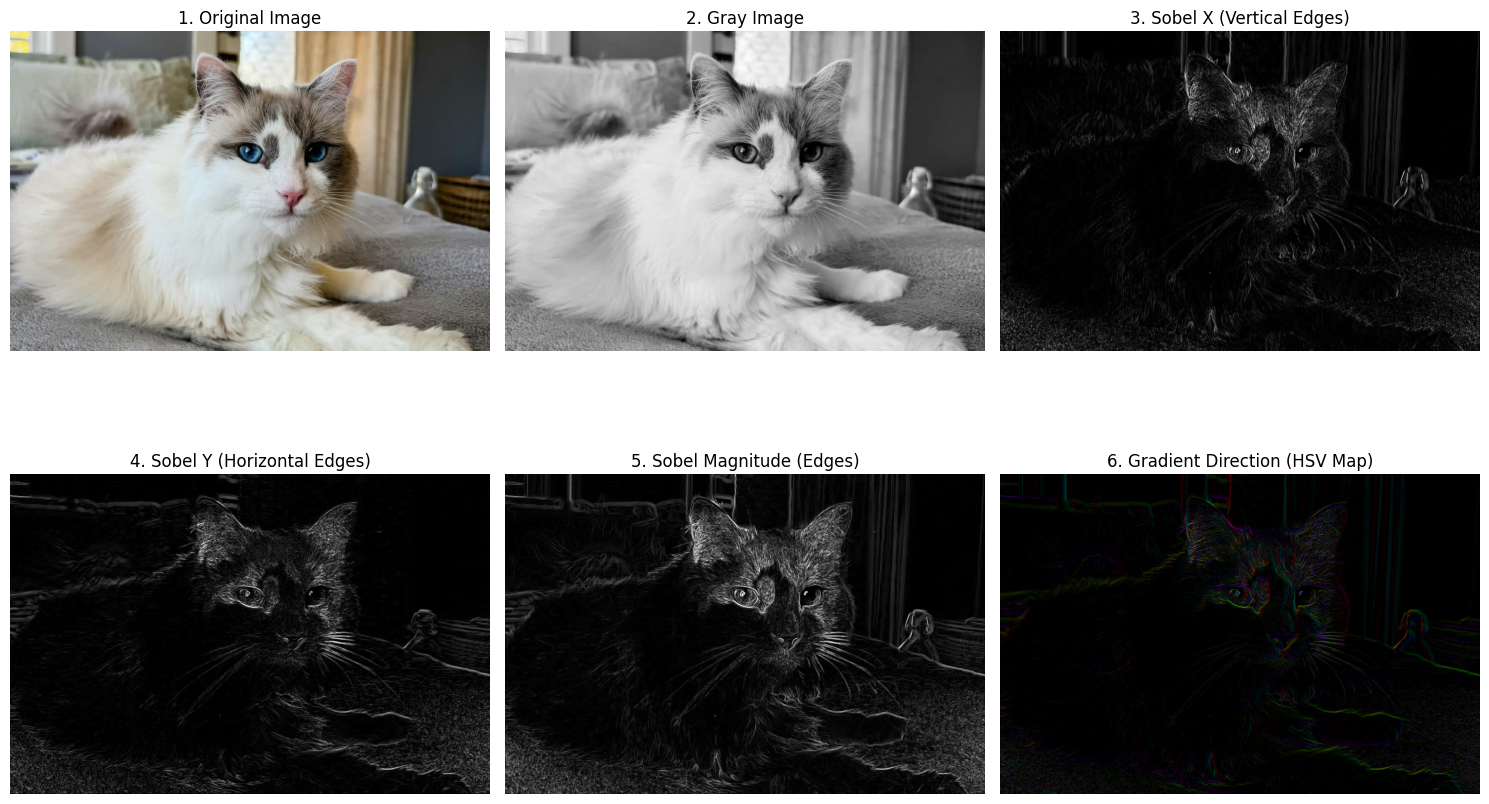

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 讀取影像並檢查
img = cv2.imread('Ragdoll.png')
if img is None:
    raise FileNotFoundError("找不到影像檔案，請確認路徑與檔名是否正確。")

# 轉換為灰階
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 可選：預先高斯模糊以減少細微雜訊干擾
gray_blur = cv2.GaussianBlur(gray, (3, 3), 0)

# 2. 分別計算 X 與 Y 方向的 Sobel 梯度 (使用 CV_64F 保留負值)
sobel_x = cv2.Sobel(gray_blur, ddepth=cv2.CV_64F, dx=1, dy=0, ksize=3)
sobel_y = cv2.Sobel(gray_blur, ddepth=cv2.CV_64F, dx=0, dy=1, ksize=3)

# 3. 取絕對值並轉回 uint8 (供單方向視覺化)
abs_sobel_x = cv2.convertScaleAbs(sobel_x)
abs_sobel_y = cv2.convertScaleAbs(sobel_y)

# 4. 計算精確梯度大小 (Magnitude) 與方向角度 (Angle, 0° ~ 360°)
magnitude, angle = cv2.cartToPolar(sobel_x, sobel_y, angleInDegrees=True)
sobel_exact = cv2.convertScaleAbs(magnitude)

# 5. 視覺化梯度方向：利用 HSV 色彩空間編碼
#    - Hue (色相): 代表方向 (OpenCV 的 H 範圍為 0~180，故將 0~360° 除以 2)
#    - Saturation (飽和度): 固定設為 255 (純色)
#    - Value (明度): 設為正規化後的梯度強度 (邊緣處亮，平坦處暗)
hsv = np.zeros((gray.shape[0], gray.shape[1], 3), dtype=np.uint8)
hsv[..., 0] = (angle / 2.0).astype(np.uint8)             # 色相代表梯度指向的方向
hsv[..., 1] = 255                                      # 飽和度拉滿
hsv[..., 2] = cv2.normalize(magnitude, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# 轉為 RGB 供 Matplotlib 正常顯示色彩
rgb_direction = cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)

# 6. 使用 Matplotlib 統一以 2x3 排版顯示
titles = [
    '1. Original Image',
    '2. Gray Image',
    '3. Sobel X (Vertical Edges)',
    '4. Sobel Y (Horizontal Edges)',
    '5. Sobel Magnitude (Edges)',
    '6. Gradient Direction (HSV Map)'
]

images = [
    cv2.cvtColor(img, cv2.COLOR_BGR2RGB),  # BGR 轉 RGB
    gray,
    abs_sobel_x,
    abs_sobel_y,
    sobel_exact,
    rgb_direction                          # 方向彩色圖
]

plt.figure(figsize=(15, 10))

for i in range(6):
    plt.subplot(2, 3, i + 1)
    if i in [0, 5]:
        plt.imshow(images[i])              # 彩色顯示 (原圖與方向圖)
    else:
        plt.imshow(images[i], cmap='gray') # 灰階顯示 (單通道強度圖)
    plt.title(titles[i], fontsize=12)
    plt.axis('off')

plt.tight_layout()
plt.show()


### Sobel 影像梯度視覺化：各圖物理與數學意義解析

在 Sobel 運算子與梯度視覺化的 $2 \times 3$ 版面中，每張圖分別代表了影像處理在「邊緣與特徵擷取」流程中的不同處理階段與數學物理意涵：

---

1. Original Image（原始彩色影像）

* **數學表示**：三維張量 $f(x, y, c)$，其中 $c \in \{R, G, B\}$。
* **物理意涵**：真實場景的高維度訊號，包含色彩、紋理、光影與環境雜訊。
* **角色定位**：提供最完整的視覺資訊基準，但因通道數多且色彩變化複雜，不適合作為純幾何邊緣分析的直接輸入。

---

2. Gray Image（灰階強度影像）

* **數學表示**：二維離散強度純量場 $f(x, y) \in [0, 255]$。
* **物理意涵**：將三通道色彩壓縮為單一的**光學亮度（Luminance）**。
* **為什麼需要**：梯度與微分的本質是衡量「亮度的空間變化率」。去除色彩冗餘資訊、保留明暗層次，是執行二維空間微積分運算的標準前置作業。

---

3. Sobel X (Vertical Edges)（水平微分響應圖）

* **數學公式**：
  $g_x = \frac{\partial f}{\partial x} \approx S_x * f$
* **物理意涵**：**水平方向的像素亮度變化率，專門偵測「垂直走向」的邊緣**。
* **視覺特徵**：
  * 當影像由左向右發生明暗突變時，微分值極大，因此**垂直線條**（如垂直立起的耳朵側緣、窗框豎欄、牆角立柱）呈現高亮。
  * 完全沿水平方向延伸的線條在此圖中微分值接近 $0$，呈現暗色或隱形。

---

4. Sobel Y (Horizontal Edges)（垂直微分響應圖）

* **數學公式**：
  $g_y = \frac{\partial f}{\partial y} \approx S_y * f$
* **物理意涵**：**垂直方向的像素亮度變化率，專門偵測「水平走向」的邊緣**。
* **視覺特徵**：
  * 當影像由上至下發生明暗突變時，微分值極大，因此**水平線條**（如閉合眼瞼橫線、橫向延伸的鬍鬚、桌面水平邊緣）呈現高亮。
  * 純垂直方向的線條在此圖中被有效抑制與濾除。

---

5. Sobel Magnitude (Edges)（梯度大小 / 邊緣強度圖）

* **數學公式**：
  $M(x, y) = \|\nabla f\| = \sqrt{g_x^2 + g_y^2}$
* **物理意涵**：**全方向梯度的長度，代表該像素點輪廓變化的劇烈程度（等向性資訊）**。
* **視覺特徵**：
  * 融合了水平與垂直的微分能量。無論輪廓走向是水平、垂直還是任意斜向，只要明暗對比足夠強烈，均呈現明顯白色線條。
  * 形成了物體輪廓的**全向邊緣圖（Full Edge Map）**，是後續邊緣細化（如 Canny NMS）或二值化分割的依據。

---

6. Gradient Direction (HSV Map)（梯度方向色彩映射圖）

* **數學公式**：
  $\theta(x, y) = \arctan\left(\frac{g_y}{g_x}\right) \in [0^\circ, 360^\circ)$
  * **色相（Hue）**：$\text{Hue} = \frac{\theta}{2} \in [0, 180)$
  * **飽和度（Saturation）**：$S = 255$
  * **明度（Value）**：$V = \text{Normalize}(M(x, y)) \in [0, 255]$
* **物理意涵**：**將幾何向量的「方向」與「強度」同步解碼呈現**。
* **視覺特徵**：
  * **顏色區分幾何走向**：不同朝向的邊緣會被賦予相異的色相（例如指向右方的梯度與指向左方的梯度顏色不同），直觀呈現邊緣幾何法線方向。
  * **平坦區域自動遮罩**：因為利用梯度大小 $M(x, y)$ 調控明度 $V$，無邊緣的背景區域強度接近 $0$ 而維持黑色，抑制雜訊色塊干擾。
* **實務關聯**：此方向資訊為現代經典特徵擷取演算法（如 **SIFT** 的主方向指派、**HOG** 的方向直方圖特徵）的關鍵核心。


## 2.2 Scharr 運算子：cv2.Scharr

### OpenCV 影像梯度進階：Scharr 運算子 (`cv2.Scharr`)
在數位影像邊緣偵測與梯度計算中，Sobel 算子雖然廣泛應用，但其在核尺寸極小時存在嚴重的幾何估算缺陷。**Scharr 運算子（Scharr Operator）** 是由 H. Scharr 針對 $3 \times 3$ 尺寸微分核進行數值最佳化所提出的改良算子，能提供更高的**旋轉不變性（Rotational Invariance）**與更準確的梯度方向估計。

---

一、 理論背景：Sobel 的幾何缺陷與 Scharr 的提出

1. Sobel 的旋轉非等向性誤差 (Rotational Anisotropy)
理想的連續空間梯度大小應該是等向的（Isotropic）：即影像中一條直線無論以 $0^\circ$（水平）、$90^\circ$（垂直）還是 $45^\circ$（斜向）放置，其計算出的梯度強度理論上應當完全一致。然而，標準的 $3 \times 3$ Sobel 算子在離散網格近似時，其平滑向量使用常規二項式加權係數 $\begin{bmatrix} 1 & 2 & 1 \end{bmatrix}^T$。當邊緣走向偏離主座標軸時（例如對角線 $45^\circ$ 方向），會產生高達數個百分點的**梯度大小偏差**以及顯著的**法線角度估算誤差**。

2. Scharr 的最佳化目標
H. Scharr 透過最小化離散傅立葉頻域下的方向逼近誤差（Orientation Error），重新計算出 $3 \times 3$ 鄰域內離散導數的最優權重係數：
* **最大化旋轉對稱性**：使不同角度傾斜的物體輪廓獲得一致的強度響應。
* **精準估計幾何朝向**：特別適合依賴梯度方向統計的特徵描述演算法（如 SIFT、HOG）。

---

二、 數學定義與卷積核比對 (Convolution Kernels)

兩者在架構上均為一維有限差分算子與一維正交平滑濾波器的張量積（Tensor Product），但核心權重比值截然不同：

1. 水平方向梯度 $g_x$（偵測垂直走向邊緣）

* **標準 $3 \times 3$ Sobel 核**：
  $S_x = \begin{bmatrix} -1 & 0 & 1 \\ -2 & 0 & 2 \\ -1 & 0 & 1 \end{bmatrix} = \begin{bmatrix} 1 \\ 2 \\ 1 \end{bmatrix} \times \begin{bmatrix} -1 & 0 & 1 \end{bmatrix}$
  * 平滑向中心權重比：$\frac{2}{1} = 2.0$

* **最佳化 $3 \times 3$ Scharr 核**：
  $K_x = \begin{bmatrix} -3 & 0 & 3 \\ -10 & 0 & 10 \\ -3 & 0 & 3 \end{bmatrix} = \begin{bmatrix} 3 \\ 10 \\ 3 \end{bmatrix} \times \begin{bmatrix} -1 & 0 & 1 \end{bmatrix}$
  * 平滑向中心權重比：$\frac{10}{3} \approx 3.33$（逼近頻域最佳化解析解）

---

2. 垂直方向梯度 $g_y$（偵測水平走向邊緣）

* **標準 $3 \times 3$ Sobel 核**：
  $S_y = \begin{bmatrix} -1 & -2 & -1 \\ 0 & 0 & 0 \\ 1 & 2 & 1 \end{bmatrix} = \begin{bmatrix} -1 \\ 0 \\ 1 \end{bmatrix} \times \begin{bmatrix} 1 & 2 & 1 \end{bmatrix}$

* **最佳化 $3 \times 3$ Scharr 核**：
  $K_y = \begin{bmatrix} -3 & -10 & -3 \\ 0 & 0 & 0 \\ 3 & 10 & 3 \end{bmatrix} = \begin{bmatrix} -1 \\ 0 \\ 1 \end{bmatrix} \times \begin{bmatrix} 3 & 10 & 3 \end{bmatrix}$

---

3. 卷積增益差異 (Kernel Energy)
* **Sobel 係數絕對值和**：$\sum |w_{ij}| = 1 + 2 + 1 + 1 + 2 + 1 = 8$
* **Scharr 係數絕對值和**：$\sum |w_{ij}| = 3 + 10 + 3 + 3 + 10 + 3 = 32$

> **結論**：Scharr 算子的原始數值能量是 Sobel 的 4 倍。因此，Scharr 對影像中的**微弱邊緣、細小毛髮與微小紋理**具有更強烈的高頻響應放大效應。

---



三、 OpenCV 語法與雙呼叫介面

在 OpenCV 中，執行 Scharr 運算有兩種完全等價的 API 呼叫方式：

介面一：專用函式 `cv2.Scharr()`
```python
dst = cv2.Scharr(src, ddepth, dx, dy[, dst[, scale[, delta[, borderType]]]])
```


介面一：專用函式 `cv2.Scharr()`

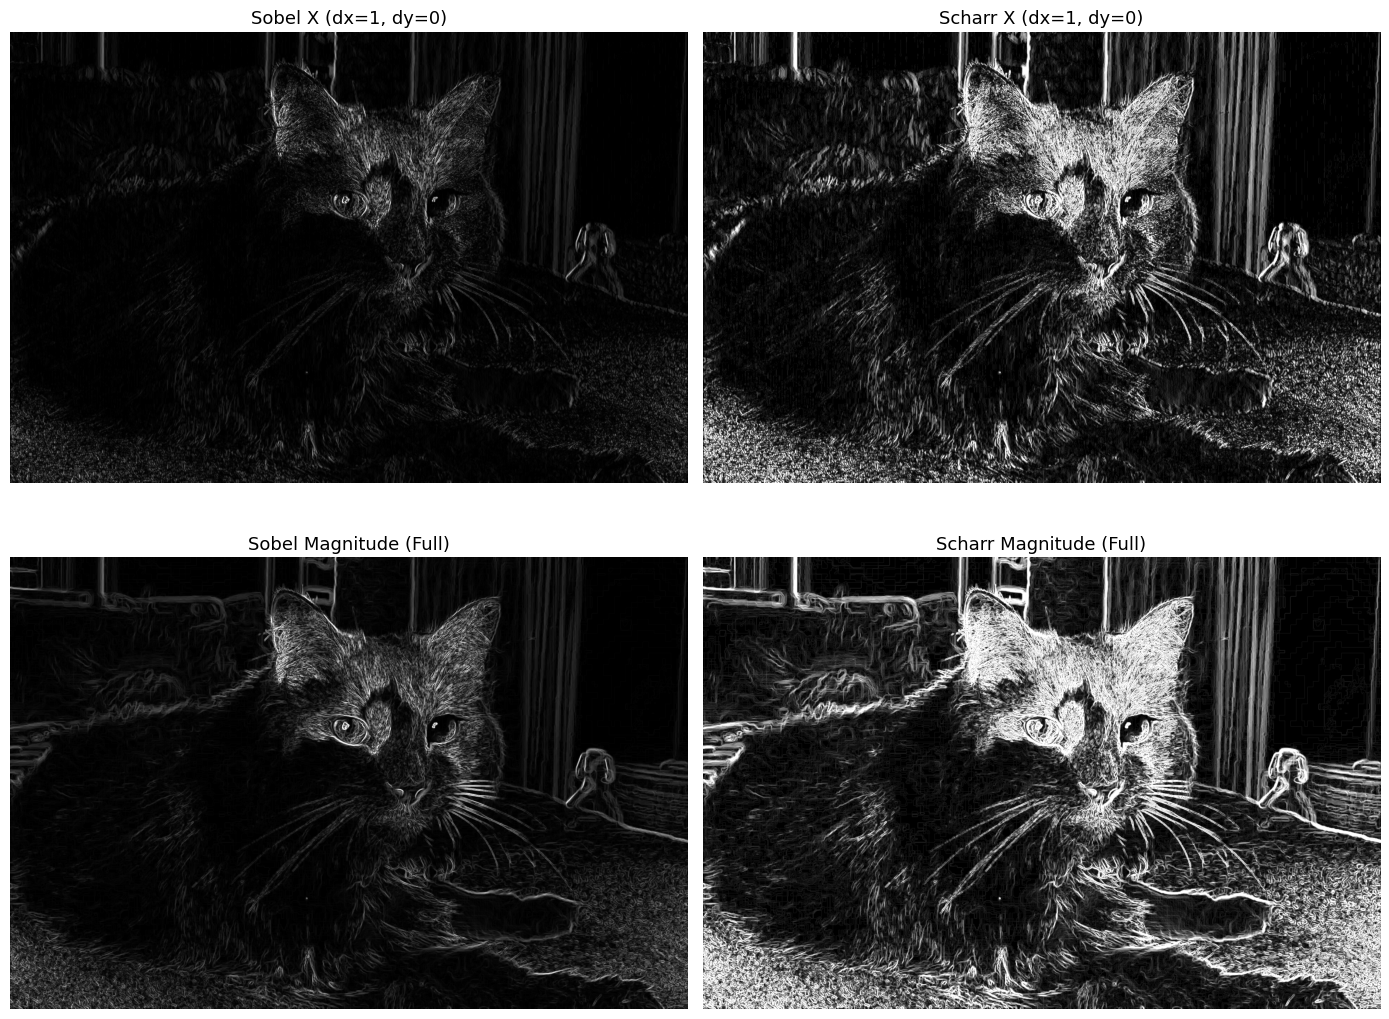

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 讀取影像並轉為灰階
img = cv2.imread('Ragdoll.png')
if img is None:
    raise FileNotFoundError("請確認影像路徑正確。")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
gray_blur = cv2.GaussianBlur(gray, (3, 3), 0)

# 2. 計算 3x3 Sobel 梯度
sobel_x = cv2.Sobel(gray_blur, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray_blur, cv2.CV_64F, 0, 1, ksize=3)
sobel_mag = cv2.magnitude(sobel_x, sobel_y)
sobel_mag_8u = cv2.convertScaleAbs(sobel_mag)

# 3. 計算 3x3 Scharr 梯度 (兩種寫法皆可，此處示範 cv2.Scharr)
scharr_x = cv2.Scharr(gray_blur, cv2.CV_64F, 1, 0)
scharr_y = cv2.Scharr(gray_blur, cv2.CV_64F, 0, 1)
scharr_mag = cv2.magnitude(scharr_x, scharr_y)
scharr_mag_8u = cv2.convertScaleAbs(scharr_mag)

# 4. 取出 X 方向絕對值供細節比對
sobel_x_8u = cv2.convertScaleAbs(sobel_x)
scharr_x_8u = cv2.convertScaleAbs(scharr_x)

# 5. 使用 Matplotlib 進行對比顯示
titles = [
    'Sobel X (dx=1, dy=0)', 'Scharr X (dx=1, dy=0)',
    'Sobel Magnitude', 'Scharr Magnitude'
]
images = [sobel_x_8u, scharr_x_8u, sobel_mag_8u, scharr_mag_8u]

plt.figure(figsize=(12, 10))
for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i], fontsize=13)
    plt.axis('off')

plt.tight_layout()
plt.show()


介面二：效果與 cv2.Scharr(src, ddepth, dx=1, dy=0) 完全等價
```python
dst = cv2.Sobel(src, ddepth, dx=1, dy=0, ksize=cv2.FILTER_SCHARR) # 或 ksize=-1
```

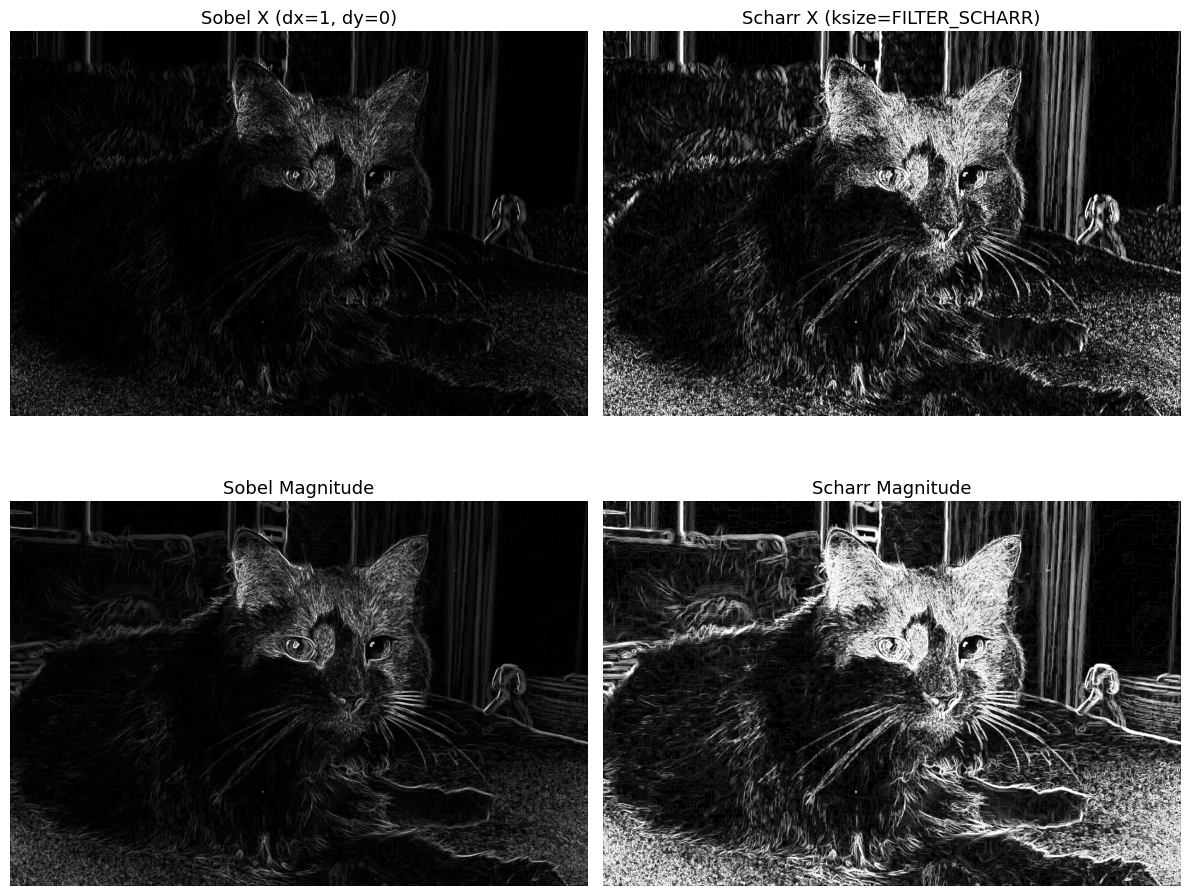

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 讀取影像並轉為灰階
img = cv2.imread('Ragdoll.png')
if img is None:
    raise FileNotFoundError("請確認影像路徑正確。")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
gray_blur = cv2.GaussianBlur(gray, (3, 3), 0)

# 2. 計算 3x3 Sobel 梯度
sobel_x = cv2.Sobel(gray_blur, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray_blur, cv2.CV_64F, 0, 1, ksize=3)
sobel_mag = cv2.magnitude(sobel_x, sobel_y)
sobel_mag_8u = cv2.convertScaleAbs(sobel_mag)

# 3. 使用 cv2.Sobel 搭配 FILTER_SCHARR (或 ksize=-1) 計算 3x3 Scharr 梯度
scharr_x = cv2.Sobel(gray_blur, cv2.CV_64F, 1, 0, ksize=cv2.FILTER_SCHARR)
scharr_y = cv2.Sobel(gray_blur, cv2.CV_64F, 0, 1, ksize=cv2.FILTER_SCHARR)
scharr_mag = cv2.magnitude(scharr_x, scharr_y)
scharr_mag_8u = cv2.convertScaleAbs(scharr_mag)

# 4. 取出 X 方向絕對值供細節比對
sobel_x_8u = cv2.convertScaleAbs(sobel_x)
scharr_x_8u = cv2.convertScaleAbs(scharr_x)

# 5. 使用 Matplotlib 進行對比顯示
titles = [
    'Sobel X (dx=1, dy=0)', 'Scharr X (ksize=FILTER_SCHARR)',
    'Sobel Magnitude', 'Scharr Magnitude'
]
images = [sobel_x_8u, scharr_x_8u, sobel_mag_8u, scharr_mag_8u]

plt.figure(figsize=(12, 10))
for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i], fontsize=13)
    plt.axis('off')

plt.tight_layout()
plt.show()

### Sobel 與 Scharr 實測結果對比分析：四張影像的幾何與物理差異

根據貓咪影像的實際運算結果，這組 $2 \times 2$ 的對比圖清晰展示了 **橫向（Sobel vs. Scharr）** 的頻率增益差異，以及 **縱向（單向 X 偏微分 vs. 全向梯度大小 Magnitude）** 的幾何方向性差異。

---

一、 左右軸對比：Sobel vs. Scharr（濾波器增益與微弱邊緣敏銳度）

* **核心數學機制**：
  * Sobel 核絕對值和：$\sum |w| = 8$
  * Scharr 核絕對值和：$\sum |w| = 32$（能量為 Sobel 的 **4 倍**）

1. 左側（Sobel 系列）：邊緣柔和、暗部純淨、抗微小雜訊
* **視覺特徵**：
  * 貓咪的主要外型輪廓清晰可見。
  * 背景簾幕縫隙、左下角深色地毯的細微纖維、以及貓咪背部的微弱暗部毛流，多數低於響應閥值而隱沒於黑色背景中。
* **物理意涵**：
  * Sobel 具有較高比重的高斯平滑作用，對高頻微弱訊號有抑制效果，輸出結果呈現**主輪廓鮮明、次要紋理被自然平滑**的特性。

2. 右側（Scharr 系列）：銳利高亮、高頻放大、毛流與紋理纖毫畢現
* **視覺特徵**：
  * **細節大幅激發**：每根微小的鬍鬚、耳朵邊緣的細絨毛、臉部與胸前的毛流走向均呈現極高對比的純白色線條。
  * **暗部細節全面浮現**：原本在 Sobel 中呈現死黑的地毯表面與背景接縫，在 Scharr 處理下顯現出豐富的網狀微結構紋理。
* **物理意涵**：
  * Scharr 重新最佳化了中央權重比（$10/3$），對高頻微分成分具有更強的放大能力，能敏銳捕捉**低對比度與微小尺度的弱邊緣**。

---

二、 上下軸對比：單向 X 微分 vs. 全向 Magnitude（方向限制與幾何完整性）

1. 上方：`X (dx=1, dy=0)`（水平偏微分，偵測垂直輪廓）
* **數學公式**：$g_x = \frac{\partial f}{\partial x}$
* **視覺特徵**：
  * **垂直線條凸顯**：背景中垂直延伸的簾幕柱條、貓咪直立耳朵的外側邊緣呈現明亮線條。
  * **水平線條缺失**：貓咪平躺的背部切線、下巴與胸口之間的橫向交界線幾乎斷裂或完全消失。
* **物理意涵**：
  * 僅保留「沿著水平軸向發生亮度躍變」的訊號，對平行於 $x$ 軸的水平走向輪廓無響應。

2. 下方：`Magnitude (Full)`（全向梯度合成大小）
* **數學公式**：$M(x, y) = \sqrt{g_x^2 + g_y^2}$
* **視覺特徵**：
  * **幾何完整閉合**：在上方 X 圖中殘缺的**眼睛橢圓輪廓**、**橫向背脊切線**以及**橫向伸展的鬍鬚**，在此圖中均被完整補齊。
* **物理意涵**：
  * 綜合了空間中所有方向的能量變化，消除了單一坐標軸的方向偏差，真實反映物體的空間邊界強度。

---

三、 四圖特徵與工程選型總結表

| 圖像位置 | 圖像名稱 | 核心視覺特徵 | 最佳工程應用場景 |
| :--- | :--- | :--- | :--- |
| **左上 (Top-Left)** | **Sobel X** | 僅保留垂直方向大尺度線條；暗部與微細毛髮被平滑濾除。 | 垂直結構定位、立柱與車道線偵測、耐雜訊需求高的場景。 |
| **右上 (Top-Right)** | **Scharr X** | 垂直線條極其銳利；垂直走向的微細毛流與纖維全面顯現。 | 垂直裂紋檢測、條碼邊界精細掃描、細毛髮分析。 |
| **左下 (Bottom-Left)** | **Sobel Magnitude** | 輪廓連續平滑；背景雜訊少；主要物體外觀邊界明確。 | **一般物體偵測、語意分割前處理、標準 Canny 邊緣偵測輸入**。 |
| **右下 (Bottom-Right)** | **Scharr Magnitude** | 能量飽和高亮；全向微細紋理、毛髮、編織纖維均強烈激發。 | **表面粗糙度分析、特徵描述子（HOG/SIFT）、低對比缺陷檢測**。 |


### Sobel 與 Scharr 核心技術特性評比 (Technical Comparison)

Sobel 與 Scharr 皆屬於「平滑濾波＋差分運算」的一階微分算子，但兩者在**核尺寸設計、旋轉等向性、方向角精確度以及細節響應能力**上存在顯著的技術差異。

---

快速對比摘要表

| 評比指標 | $3 \times 3$ Sobel 運算子 | $3 \times 3$ Scharr 運算子 | 技術差異與物理意涵 |
| :--- | :--- | :--- | :--- |
| **卷積核尺寸 ($ksize$)** | 支援奇數尺寸 ($1, 3, 5, 7$) | **嚴格固定為 $3 \times 3$** | Scharr 是針對 $3 \times 3$ 鄰域求解出的最佳化權重，無大尺寸變形。 |
| **卷積核權重比** | $1 : 2 : 1$ | **$3 : 10 : 3$** ($\approx 1 : 3.33 : 1$) | Scharr 大幅提高了中心正交位置的平滑加權比重。 |
| **濾波器增益能量 ($\sum \|w\|$)** | **8** | **32** (4 倍能量) | Scharr 的微分響應強度高，未縮放前數值範圍顯著放大。 |
| **旋轉等向性 (Rotational Isotropy)** | 較差（斜向邊緣有顯著能量衰減） | **極高（維持旋轉不變性）** | Sobel 在 $45^\circ / 135^\circ$ 對角線方向估算誤差大；Scharr 誤差極小。 |
| **梯度方向 ($\theta$) 精準度** | 較低（角度量化誤差大） | **極高（角度逼近更平滑準確）** | Scharr 能更真實反映物體邊緣的法線方向。 |
| **微弱邊緣敏銳度** | 中等（過渡較平緩） | **極高（細微輪廓對比強烈）** | Scharr 對微弱邊緣、細毛髮與微小紋理更敏感。 |
| **高頻雜訊敏感度** | 較低（平滑抗噪性較佳） | 較高（高頻增益大，易放大雜訊） | 使用 Scharr 前通常需要搭配適度的高斯平滑（Gaussian Blur）。 |
| **運算成本 (Speed)** | 極快 | 極快（兩者計算複雜度完全相同） | 皆為可分離卷積（Separable Kernel），執行耗時無實質差異。 |

---

核心技術差異深度剖析

1. 旋轉非等向性誤差 (Rotational Invariance Error)
* **Sobel 的痛點**：
  在連續數學中，理想的梯度大小應該具有旋轉不變性（即邊緣旋轉時，強度不隨角度改變）。但 $3 \times 3$ Sobel 算子在離散網格近似時，對純水平/純垂直線條（$0^\circ, 90^\circ$）響應準確，卻在斜向（$45^\circ, 135^\circ$）產生非等向性失真。
* **Scharr 的優勢**：
  H. Scharr 透過頻域最佳化最小化角度逼近誤差，推導出最佳權重係數比（約 $10/3 \approx 3.33$）。在評估傾斜邊緣的法線向量時，**角度誤差大幅低於 Sobel**。

---

2. 邊緣對比與細節增益
* **Sobel ($\sum |w| = 8$)**：
  響應值相對溫和，對於細小微弱的邊緣容易在平滑階段被淡化，適合只關注粗輪廓的場景。
* **Scharr ($\sum |w| = 32$)**：
  核係數絕對值和是 Sobel 的 4 倍，具有強烈的高頻放大作用，呈現出的梯度響應圖**對比度極高、細節輪廓更銳利鮮明**。

---

最佳應用場景選型指南

建議選用 Sobel 的情境：
1. **影像雜訊較大**：環境雜訊較高且無法進行重度平滑時，Sobel 能避免雜訊被過度放大。
2. **需要較大尺度感應野**：需要使用較大尺寸核（如 $ksize = 5$ 或 $7$）以忽略微小紋理、僅擷取大物體主輪廓時。
3. **一般通用粗邊緣二值化**：例如快速 Canny 前置處理、粗略物體偵測與背景分割。

建議選用 Scharr 的情境：
1. **高精度梯度方向特徵分析**：
   * **HOG (Histogram of Oriented Gradients)**：行人偵測與人體骨架分析。
   * **SIFT / SURF**：特徵點主方向指派（Orientation Assignment）。
2. **工業幾何量測與瑕疵檢測**：要求亞像素（Sub-pixel）邊緣定位精度、零件角度偏差量測時。
3. **低對比弱邊緣擷取**：醫學影像組織微細邊緣、精細條碼/QR Code 邊界掃描。


## 2.3 梯度幅值與方向合成：cv2.cartToPolar

### OpenCV 梯度幅值與方向合成：`cv2.cartToPolar()`

在影像邊緣偵測與特徵萃取流程中，經由 Sobel 或 Scharr 運算子取得水平差分場 $g_x$ 與垂直差分場 $g_y$ 後，下一步就是將這兩組直角坐標（Cartesian）向量轉換為極坐標（Polar）形式，以求得**梯度幅值（Magnitude / 邊緣強度）**與**梯度方向（Angle / 幾何朝向）**。

在 OpenCV 中，`cv2.cartToPolar()` 是最高效且最佳化的官方合成函式。

---

一、 數學原理：直角坐標轉極坐標 (Cartesian to Polar)

對影像中任一像素點 $(x, y)$，其梯度向量為：
$\nabla f = \begin{bmatrix} g_x \\ g_y \end{bmatrix}$

`cv2.cartToPolar()` 執行的空間映射公式如下：

1. 梯度幅值（Gradient Magnitude）
表示該像素位置的**明暗變化劇烈程度（邊緣強度）**：
$\text{magnitude}(x, y) = \|\nabla f\| = \sqrt{g_x^2 + g_y^2}$

2. 梯度方向角（Gradient Orientation / Angle）
表示**亮度增長最快的幾何向量朝向**：
$\text{angle}(x, y) = \operatorname{atan2}(g_y, g_x)$

* 內部採用 `atan2` 實現，能完整涵蓋四個象限，並自動避免 $g_x = 0$ 時的除以零例外（Zero Division Exception）。
* 角度數值範圍：
  * **弧度制（Radians）**：$[0, 2\pi)$
  * **度數制（Degrees）**：$[0^\circ, 360^\circ)$

> **坐標系提醒**：在數位影像坐標系中，水平向右為 $+x$，**垂直向下為 $+y$**（與笛卡兒幾何坐標系的 $+y$ 向上相反），在分析幾何法向量指向時需注意坐標系定義。

---

二、 `cv2.cartToPolar()` 函式語法與參數

```python
magnitude, angle = cv2.cartToPolar(x, y[, magnitude[, angle[, angleInDegrees]]])


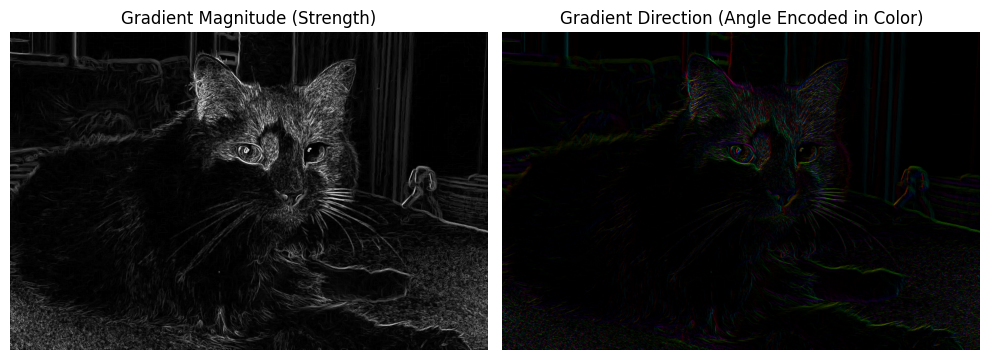

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 讀取並前處理灰階圖
img = cv2.imread('Ragdoll.png')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
gray_blur = cv2.GaussianBlur(gray, (3, 3), 0)

# 2. 計算 Sobel 偏微分 (必須保持為 CV_64F 或 CV_32F 浮點型態)
sobel_x = cv2.Sobel(gray_blur, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray_blur, cv2.CV_64F, 0, 1, ksize=3)

# 3. 使用 cv2.cartToPolar 同步合成幅值與方向
magnitude, angle = cv2.cartToPolar(sobel_x, sobel_y, angleInDegrees=True)

# 4. 幅值轉回 8-bit uint8 供一般邊緣圖顯示
edge_mag_8u = cv2.convertScaleAbs(magnitude)

# 5. 將 (Magnitude, Angle) 編碼至 HSV 色彩空間以視覺化方向：
#    - H (色相 0~180): 代表 0~360 度的幾何朝向 (angle / 2)
#    - S (飽和度 255): 鮮豔度全開
#    - V (明度 0~255): 設為幅值強度 (只有邊緣亮起，平坦無邊緣處保持黑色)
hsv = np.zeros((gray.shape[0], gray.shape[1], 3), dtype=np.uint8)
hsv[..., 0] = (angle / 2.0).astype(np.uint8)  # 色相映射角度
hsv[..., 1] = 255                            # 飽和度
hsv[..., 2] = cv2.normalize(magnitude, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# 轉為 RGB 供 Matplotlib 顯示
rgb_direction = cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)

# 6. 視覺化排版
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(edge_mag_8u, cmap='gray')
plt.title('Gradient Magnitude (Strength)', fontsize=12)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(rgb_direction)
plt.title('Gradient Direction (Angle Encoded in Color)', fontsize=12)
plt.axis('off')

plt.tight_layout()
plt.show()


### 梯度幅值與梯度方向視覺化對比分析 (Magnitude vs. Direction)

在經由 `cv2.cartToPolar()` 轉換後所呈現的這兩張影像，具體反映了二維空間向量場的兩大本質面向：
- **「幾何邊緣的強度（純量尺度）」**
- **「幾何邊緣的法線朝向（向量角度）」**

---

一、 核心概念與本質差異

| 評比維度 | 左圖：Gradient Magnitude (Strength) | 右圖：Gradient Direction (HSV Encoded) |
| :--- | :--- | :--- |
| **數學本質** | **純量場（Scalar Field）**：$M(x, y) = \sqrt{g_x^2 + g_y^2}$ | **向量屬性（Vector Field）**：$\theta(x, y) = \operatorname{atan2}(g_y, g_x)$ |
| **解析目標** | **「此處是否存在邊緣？邊緣劇烈程度為何？」** | **「此處邊緣的切線與法線朝向哪個角度？」** |
| **資訊維度** | 單通道強度（灰階：黑代表平坦、白代表強邊緣） | 三通道色彩（HSV 色相編碼角度，明度編碼強度） |
| **方向感知** | **完全無方向性（Isotropic）** | **具高度方向辨識力（Anisotropic）** |

---

二、 畫面細節與物理特徵深入解讀

1. 左圖：Gradient Magnitude（梯度幅值圖）
* **視覺特徵**：全圖為連續灰階黑白分佈。
* **物理意涵**：
  * **等向性聚合**：不論輪廓是垂直（如貓耳側邊）、水平（如背部橫線）或任意傾斜角度（如鬍鬚弧度），只要相鄰像素的亮度落差大，一律映射為**同等明亮的純白色線條**。
  * **平坦區域抑制**：背景黑色區域代表相鄰像素差值趨近於 $0$，表示亮度均勻、無物體交界。

---

2. 右圖：Gradient Direction（梯度方向色彩映射圖）
* **視覺特徵**：在輪廓與毛流處呈現豐富的**紅、黃、綠、青、藍、洋紅**等彩色線條；無邊緣處保持黑色。
* **物理意涵（色彩即幾何角度）**：
  * **色相（Hue）代表方向角 $\theta$**：
    * **垂直邊緣**（梯度水平指向，$\theta \approx 0^\circ \text{ 或 } 180^\circ$）：呈現特定色彩（如紅色/青色系）。
    * **水平邊緣**（梯度垂直指向，$\theta \approx 90^\circ \text{ 或 } 270^\circ$）：呈現相異正交色彩（如綠色/洋紅色系）。
    * 貓咪臉部左側與右側對稱的弧形毛流，因法線方向相反或旋轉，呈現出連續且平滑過渡的彩虹色彩階。
  * **明度（Value）作為訊號遮罩**：
    * 演算法將 HSV 中的 $V$（明度）綁定為梯度幅值 $M(x, y)$。
    * **抑制雜訊干擾**：平坦區域因強度接近 $0$ 而維持純黑，避免了在無邊緣的雜訊區域產生隨機亂跳的彩色雜點。

---

三、 後續演算法應用分流

這兩張圖呈現的資訊分別對應電腦視覺不同階段的運算需求：

1. 幅值圖（左圖）的核心用途：
* **邊緣偵測二值化（Thresholding）**：直接設定臨界值，保留大於門檻的像素，即可取得物體粗輪廓二值圖。
* **影像銳化（Unsharp Masking）**：將強度圖乘上係數反加回原圖，增強畫面邊界反差。

2. 方向色彩圖（右圖）的核心用途：
* **Canny 邊緣細化（非極大值抑制 Non-Maximum Suppression, NMS）**：
  * 演算法依據方向角（圖中顏色），將法線歸納至 $0^\circ, 45^\circ, 90^\circ, 135^\circ$ 四個方向。
  * 沿著該角度比對鄰近像素的強度值，僅保留局部峰值點，將數個像素寬的粗邊緣剔骨細化為「單像素極細輪廓」。
* **形狀與物體辨識（HOG / SIFT 特徵工程）**：
  * 深度特徵演算法（如行人偵測 HOG）並非單純記憶線條有多亮，而是**統計區域內的色彩分佈比例（即方向角直方圖）**。
  * 即使影像整體光影變暗或變亮，只要物體幾何形狀不變，右圖的「色彩比例分佈」就保持高度恆定，具備強大的光照不變性。


# 3.二階導數運算子與銳化 (Second-Order & Sharpening)

與一階導數（如 Sobel、Scharr 尋找梯度峰值）不同，**二階導數運算子（Second-Order Derivative Operators）** 透過計算亮度變化的「變化率」，能精準定位灰階急劇過渡的中心（**過零點，Zero-Crossing**），並廣泛應用於影像銳化（Image Sharpening）以增強邊緣與細節對比。

---

1. 一階導數 vs. 二階導數特性比較

| 比較維度 | 一階導數 (Sobel / Scharr) | 二階導數 (Laplacian) |
| :--- | :--- | :--- |
| **數學定義** | 梯度向量 $\nabla f = \left[\frac{\partial f}{\partial x}, \frac{\partial f}{\partial y}\right]$ | 純量場 $\nabla^2 f = \frac{\partial^2 f}{\partial x^2} + \frac{\partial^2 f}{\partial y^2}$ |
| **邊緣響應** | 產生較粗的邊緣帶，極值位於邊緣中心 | 產生正負雙響應，中心為 **過零點（Zero-Crossing）** |
| **方向性** | 具方向性（需分別計算 $G_x, G_y$ 再合併） | **各向同性（Isotropic）**，單一卷積核即可偵測所有方向 |
| **雜訊敏感度** | 中等 | **極高**（對孤立雜訊點與細線反應劇烈，通常需先平滑） |
| **主要用途** | 邊緣偵測、梯度方向計算 | 影像銳化、細節增強、斑點偵測（LoG） |

---

## 3.1 拉普拉斯運算子（Laplacian）：cv2.Laplacian

核心原理
拉普拉斯運算子是一種**二階空間微分運算子**，用來計算影像灰階值的曲率（即梯度變化的速率）。其連續數學定義為：

$\nabla^2 f(x, y) = \frac{\partial^2 f}{\partial x^2} + \frac{\partial^2 f}{\partial y^2}$

與一階導數不同，拉普拉斯運算子具有**各向同性（Isotropic / 旋轉不變性）**，不需像 Sobel 分別計算 X 與 Y 方向，單一卷積核即可同時偵測所有方向的邊緣。在離散影像中，常見的 $3 \times 3$ 卷積核為 4-鄰域與 8-鄰域形式：

$K_4 = \begin{bmatrix} 0 & 1 & 0 \\ 1 & -4 & 1 \\ 0 & 1 & 0 \end{bmatrix}, \quad K_8 = \begin{bmatrix} 1 & 1 & 1 \\ 1 & -8 & 1 \\ 1 & 1 & 1 \end{bmatrix}$

OpenCV 語法與關鍵參數
```python
dst = cv2.Laplacian(src, ddepth, ksize=1, scale=1, delta=0, borderType=cv2.BORDER_DEFAULT)
```

* **`src`**：輸入影像（通常先轉為灰階）。
* **`ddepth`**：輸出影像的資料深度。**實務上必須設為 `cv2.CV_64F` 或 `cv2.CV_16S`**，因為二階導數在邊緣兩側會產生正、負值；若直接設為 `cv2.CV_8U`，負值會被截斷為 0，導致一半的邊緣資訊遺失。
* **`ksize`**：計算二階導數所使用的濾波器大小（必須為正奇數）。
  * `ksize=1`（預設）：直接使用上述的 $3 \times 3$ 基礎 $K_4$ 卷積核。
  * `ksize > 1`（如 `3`, `5`）：底層會改用 Sobel 運算子近似計算二階偏導數的總和。

特性與限制
* **優點**：計算快速、無方向偏差，對細微紋理與孤立點響應強烈。
* **缺點**：**對雜訊極度敏感**。二階微分會將影像中的高頻雜訊大幅放大，因此實務上極少單獨對未降噪的原圖直接使用。

---


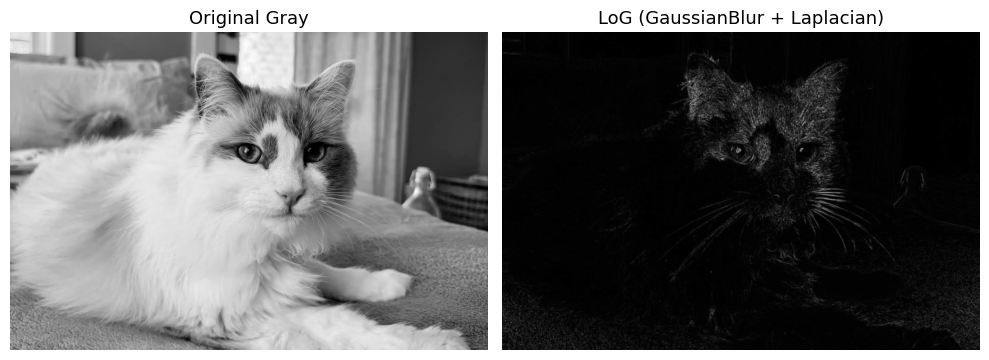

In [8]:
import cv2
import matplotlib.pyplot as plt

# 1. 讀取影像並轉為灰階
img = cv2.imread('Ragdoll.png')
if img is None:
    raise FileNotFoundError("請確認影像路徑正確。")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 2. 先高斯平滑降噪，再計算 Laplacian (使用 CV_64F 保留正負號)
gray_blur = cv2.GaussianBlur(gray, (3, 3), 0)
laplacian = cv2.Laplacian(gray_blur, cv2.CV_64F, ksize=3)

# 3. 取絕對值並轉回 8-bit 供顯示
log_result = cv2.convertScaleAbs(laplacian)

# 4. 顯示對比結果
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(gray, cmap='gray')
plt.title('Original Gray', fontsize=13)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(log_result, cmap='gray')
plt.title('LoG (GaussianBlur + Laplacian)', fontsize=13)
plt.axis('off')

plt.tight_layout()
plt.show()

## 3.2 高斯拉普拉斯（LoG, Laplacian of Gaussian）

設計動機
為了解決 Laplacian 運算子對雜訊過度敏感的致命傷，Marr 與 Hildreth 提出了 **LoG（Laplacian of Gaussian）** 演算法：在進行二階微分之前，先對影像套用高斯低通濾波器（Gaussian Blur）濾除高頻雜訊。

數學與物理意義
根據卷積的結合律與微分性質，先做高斯平滑再做拉普拉斯運算，等效於直接將原圖與「高斯函數的拉普拉斯核（形狀類似墨西哥帽，Mexican Hat）」進行卷積：

$\text{LoG}(x, y) = \nabla^2 \left[ G_\sigma(x, y) * f(x, y) \right] = \left[ \nabla^2 G_\sigma(x, y) \right] * f(x, y)$

其中 $\sigma$ 為高斯函數的標準差，決定了平滑尺度：
* **$\sigma$ 較小**：保留更多細部邊緣，但抗噪能力較弱。
* **$\sigma$ 較大**：抗噪能力強，僅偵測大尺度的主要輪廓（粗邊緣）。

實作流程（OpenCV 兩階段法）
在 OpenCV 中，最直覺且高效的 LoG 實作方式是串接兩個現成函式：
1. **高斯平滑降噪**：`blur = cv2.GaussianBlur(gray, (3, 3), 0)`
2. **計算二階導數**：`lap = cv2.Laplacian(blur, cv2.CV_64F, ksize=3)`
3. **視覺化轉換**：`log_8u = cv2.convertScaleAbs(lap)`（取絕對值並轉回 8-bit 顯示）

應用場景
* 抗噪型邊緣偵測（進階應用會搭配**過零點偵測，Zero-Crossing** 精準定位單像素寬度的邊緣）。
* 多尺度斑點偵測（Blob Detection），也是後續 DoG（Difference of Gaussians，SIFT 特徵演算法核心）的理論基礎。


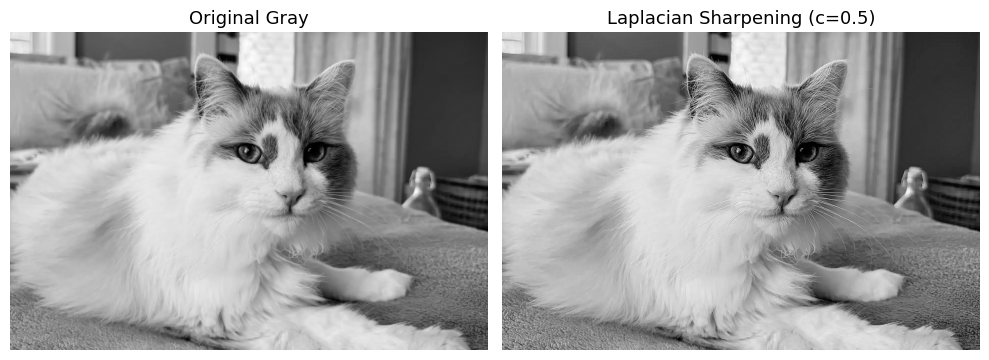

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 讀取影像並轉為灰階
img = cv2.imread('Ragdoll.png')
if img is None:
    raise FileNotFoundError("請確認影像路徑正確。")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 2. 計算 Laplacian 二階導數 (可依雜訊程度決定是否先輕微平滑)
gray_blur = cv2.GaussianBlur(gray, (3, 3), 0)
laplacian = cv2.Laplacian(gray_blur, cv2.CV_64F, ksize=3)

# 3. 執行銳化：原圖 - c * Laplacian，並裁切至 [0, 255]
c = 0.5  # 銳化強度係數 (建議 0.2 ~ 1.0)
sharpened = gray.astype(np.float64) - c * laplacian
sharpened_lap = np.clip(sharpened, 0, 255).astype(np.uint8)

# 4. 顯示對比結果
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(gray, cmap='gray')
plt.title('Original Gray', fontsize=13)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(sharpened_lap, cmap='gray')
plt.title(f'Laplacian Sharpening (c={c})', fontsize=13)
plt.axis('off')

plt.tight_layout()
plt.show()

## 3.3 反銳化遮罩（Unsharp Masking, USM）銳化增強

**反銳化遮罩（Unsharp Masking, USM）** 是工業界、攝影後製（如 Photoshop）與電腦視覺中最常使用的影像銳化技術。其名稱源自傳統暗房沖洗技術：利用一張「模糊（Unsharp）的負片」作為遮罩，來反襯並強化原圖的清晰細節。

數學原理與三步驟
USM 的核心思想是「萃取高頻細節，再疊加回原圖」：

1. **產生低頻模糊圖**：對原圖 $f(x, y)$ 進行高斯模糊，得到僅保留低頻輪廓的 $f_{\text{blur}}(x, y)$。
2. **萃取高頻細節遮罩（Mask）**：將原圖減去模糊圖，即可分離出邊緣與紋理等高頻訊號：
   $g_{\text{mask}}(x, y) = f(x, y) - f_{\text{blur}}(x, y)$
3. **加權疊加回原圖**：將細節遮罩乘上強度係數 $k$ 後加回原圖：
   $g(x, y) = f(x, y) + k \cdot \left[ f(x, y) - f_{\text{blur}}(x, y) \right]$

將公式化簡後，可直接寫為兩張影像的線性加權組合：
$g(x, y) = (1 + k) \cdot f(x, y) - k \cdot f_{\text{blur}}(x, y)$

* **$k = 1$**：標準反銳化遮罩（Unsharp Masking）。
* **$k > 1$**：高提升濾波（High-Boost Filtering），銳化效果更強烈。

OpenCV 高效實作
利用 `cv2.addWeighted` 可一行完成 USM 運算，且底層會自動執行飽和裁切（`saturate_cast`），避免 `uint8` 數值溢位產生偽影：

```python
blur = cv2.GaussianBlur(img, (5, 5), 1.0)
k = 1.5
sharpened = cv2.addWeighted(img, 1 + k, blur, -k, 0)
```

實務優勢與注意事項
* **控制彈性高**：可透過高斯核的 $\sigma$ 控制「銳化影響的邊緣寬度（半徑）」，透過 $k$ 控制「銳化強度」，比單純的 Laplacian 銳化更容易調校出自然的效果。
* **彩色影像建議**：若直接對 RGB/BGR 三通道執行 USM，強烈邊緣處可能出現不自然的色偏（Color Fringing）。較佳的工程做法是將影像轉至 **LAB** 或 **YCrCb** 色彩空間，**僅對亮度通道（L 或 Y）執行 USM**，再轉回 BGR。


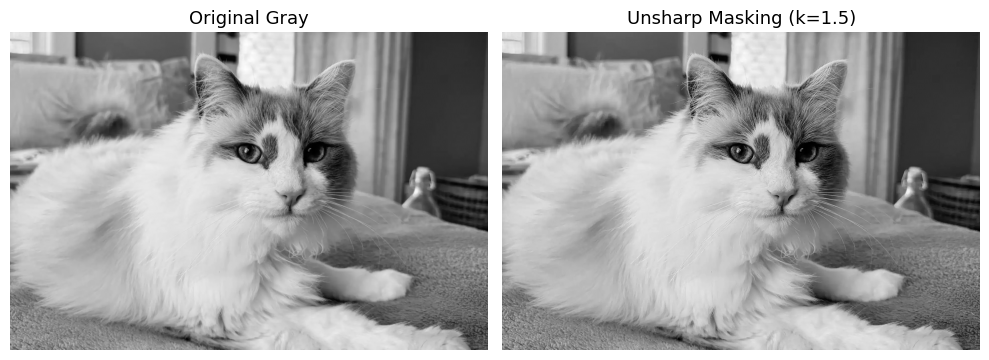

In [10]:
import cv2
import matplotlib.pyplot as plt

# 1. 讀取影像並轉為灰階
img = cv2.imread('Ragdoll.png')
if img is None:
    raise FileNotFoundError("請確認影像路徑正確。")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 2. 產生低頻模糊影像
gray_blur = cv2.GaussianBlur(gray, (5, 5), 1.0)

# 3. 執行 USM 銳化：原圖 * (1 + k) + 模糊圖 * (-k)
# cv2.addWeighted 底層會自動處理飽和裁切 (saturate_cast)，不需手動 clip
k = 1.5  # 銳化強度 (k=1 為標準 USM，k>1 為高提升濾波 High-Boost)
sharpened_usm = cv2.addWeighted(gray, 1 + k, gray_blur, -k, 0)

# 4. 顯示對比結果
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(gray, cmap='gray')
plt.title('Original Gray', fontsize=13)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(sharpened_usm, cmap='gray')
plt.title(f'Unsharp Masking (k={k})', fontsize=13)
plt.axis('off')

plt.tight_layout()
plt.show()

## 3.4. 三者核心特性總覽比較

| 技術名稱 | 運算本質 | 抗噪能力 | 主要用途 | OpenCV 核心函式 |
| :--- | :--- | :--- | :--- | :--- |
| **Laplacian** | 純二階空間微分 | 極低（易放大雜訊） | 基礎邊緣偵測、簡易銳化 | `cv2.Laplacian` |
| **LoG** | 高斯平滑 + 二階微分 | 中～高（由 $\sigma$ 控制） | 抗噪邊緣偵測、斑點偵測 | `cv2.GaussianBlur` + `cv2.Laplacian` |
| **USM** | 原圖 + 加權高頻差值 | 高（可獨立調控半徑與強度） | 實務影像銳化、細節增強 | `cv2.GaussianBlur` + `cv2.addWeighted` |

# 4.Canny 邊緣偵測演算法

**Canny 邊緣偵測演算法**由 John F. Canny 於 1986 年提出，至今仍是電腦視覺領域公認的**黃金標準（The Gold Standard）**。與單純計算微分的 Sobel 或 Laplacian 不同，Canny 是一套完整的多階段演算法，旨在同時滿足最佳邊緣偵測的三大準則：

* **低錯誤率（Low Error Rate）**：盡可能偵測出所有真實邊緣，同時將雜訊誤判降至最低。
* **精準定位（Good Localization）**：偵測到的邊緣像素必須盡可能貼近真實邊緣中心。
* **單一響應（Minimal Response）**：同一條真實邊緣只應被標記為**單一像素寬度**的細線，避免產生粗邊緣或雙重邊緣。

---

1. Canny 演算法四大核心步驟

- 步驟一：高斯濾波降噪（Gaussian Smoothing）
邊緣偵測對高頻雜訊極度敏感，因此先對灰階影像套用高斯濾波器（常見為 $5 \times 5$ 核心），濾除孤立雜訊點並平滑微小紋理干擾。

- 步驟二：計算梯度強度與方向（Gradient Calculation）
  對平滑後的影像分別沿水平與垂直方向套用 Sobel 運算子取得 $G_x$ 與 $G_y$，接著計算每個像素的**梯度強度（Magnitude）**與**梯度方向（Direction）**：

  $G = \sqrt{G_x^2 + G_y^2} \quad (\text{或 } L_1 \text{ 近似 } \vert{}G_x\vert{} + \vert{}G_y\vert{})$

  $\theta = \text{atan2}(G_y, G_x)$

  梯度方向 $\theta$ 永遠**垂直於邊緣走向**，並會被量化為四個離散方向：$0^\circ$（水平）、$45^\circ$（斜角）、$90^\circ$（垂直）、$135^\circ$（反斜角）。

- 步驟三：非極大值抑制（Non-Maximum Suppression, NMS）
  這是 Canny 能產生「單像素細邊緣」的關鍵。演算法沿著每個像素的**梯度方向**，檢查該像素是否為局部最大值：
  * 若當前像素的梯度強度大於沿梯度方向前後兩側的相鄰像素，則保留作為候選邊緣。
  * 若否，則將該像素的數值抑制歸零（設為 0），藉此將原本較粗的梯度帶「削薄」成單像素寬度。

- 步驟四：雙閾值與滯後邊緣連接（Hysteresis Thresholding）
單一閾值容易陷入「設太高會斷線、設太低會充滿雜訊」的兩難。Canny 引入**高閾值（`maxVal`）**與**低閾值（`minVal`）**將候選像素分為三類：

| 像素分類 | 判斷條件 | 處理方式 |
| :--- | :--- | :--- |
| **強邊緣（Strong Edge）** | 梯度值大於 `maxVal` | 直接判定為真實邊緣並保留。 |
| **弱邊緣（Weak Edge）** | 介於 `minVal` 與 `maxVal` 之間 | **視連通性決定**：若與「強邊緣」相連（8-連通），則保留為真實邊緣；若為孤立點或未連接到強邊緣，則視為雜訊剔除。 |
| **非邊緣（Non-Edge）** | 梯度值小於 `minVal` | 直接捨棄（歸零）。 |

---


2. OpenCV `cv2.Canny` 語法與參數解析

```python
edges = cv2.Canny(image, threshold1, threshold2, apertureSize=3, L2gradient=False)
```

* **`image`**：輸入的 8-bit 單通道灰階影像（`uint8`）。
* **`threshold1`**：滯後程序的**低閾值（`minVal`）**。
* **`threshold2`**：滯後程序的**高閾值（`maxVal`）**。實務經驗法則通常建議 `threshold1 : threshold2` 設為 **1:2 或 1:3**（例如 `50, 150`）。
* **`apertureSize`**：內部計算 Sobel 梯度的核心大小，預設為 `3`（可設為 `3`, `5`, `7`）。
* **`L2gradient`**：梯度強度計算公式旗標。
  * `False`（預設）：使用計算較快的 $L_1$ 範數 $\vert{}G_x\vert{} + \vert{}G_y\vert{}$。
  * `True`：使用精確的 $L_2$ 歐幾里得範數 $\sqrt{G_x^2 + G_y^2}$，邊緣定位更精準，但運算量略高。

---

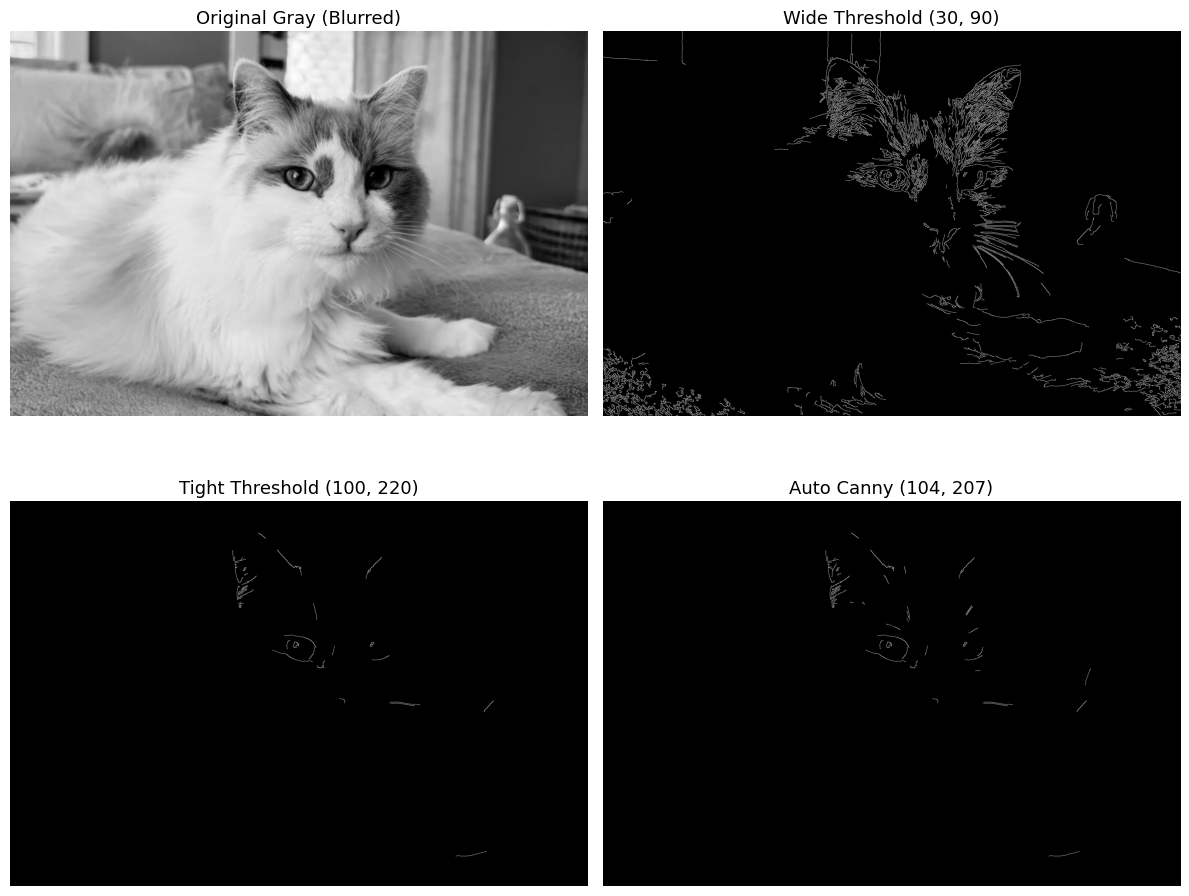

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def auto_canny(image, sigma=0.33):
    """依據影像灰階中位數自動計算 Canny 雙閾值"""
    v = np.median(image)
    lower = int(max(0, (1.0 - sigma) * v))
    upper = int(min(255, (1.0 + sigma) * v))
    return cv2.Canny(image, lower, upper, L2gradient=True), lower, upper

# 1. 讀取影像並轉為灰階，先進行高斯平滑降噪
img = cv2.imread('Ragdoll.png')
if img is None:
    raise FileNotFoundError("請確認影像路徑正確。")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (5, 5), 1.4)

# 2. 不同閾值設定的 Canny 邊緣偵測
# 寬鬆閾值：保留大量細節，但容易混入背景紋理雜訊
canny_wide = cv2.Canny(blur, 30, 90, L2gradient=True)

# 嚴格閾值：僅保留對比強烈的主要輪廓
canny_tight = cv2.Canny(blur, 100, 220, L2gradient=True)

# 自動閾值 (Auto-Canny)
canny_auto, low_t, high_t = auto_canny(blur, sigma=0.33)

# 3. 2x2 對比顯示
titles = [
    'Original Gray (Blurred)',
    'Wide Threshold (30, 90)',
    'Tight Threshold (100, 220)',
    f'Auto Canny ({low_t}, {high_t})'
]
images = [blur, canny_wide, canny_tight, canny_auto]

plt.figure(figsize=(12, 10))
for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i], fontsize=13)
    plt.axis('off')

plt.tight_layout()
plt.show()

Canny 邊緣偵測四圖結果差異分析

這四張圖展示了同一張布偶貓影像在經過高斯平滑後，套用不同 Canny 雙閾值（`threshold1`, `threshold2`）所產生的邊緣偵測差異：

| 位置與標題 | 視覺呈現與邊緣特徵 | 原因與特性分析 |
| :--- | :--- | :--- |
| **左上：Original Gray (Blurred)**| 經過灰階化與高斯模糊處理的原圖，貓咪毛髮與背景過渡較柔和。 | 作為後續三張 Canny 運算的共同輸入影像，已先濾除部分高頻雜訊。 |
| **右上：Wide Threshold (30, 90)**| **細節最豐富**，完整勾勒出貓咪的雙耳、五官、鬍鬚、右側背景擺飾，但底部毛毯也出現大量碎裂紋理雜訊。 | 閾值設定較低，連微弱的梯度變化都被保留；適合需要完整輪廓的場景，但抗背景雜訊能力較差。 |
| **左下：Tight Threshold (100, 220)** | **畫面幾乎全黑**，僅剩下對比最強烈的局部輪廓（如眼睛邊緣、左耳局部與少許鬍鬚線條）。 | 閾值極高，絕大多數柔和的毛髮與身體邊緣梯度都低於門檻而被濾除，導致輪廓嚴重斷裂。 |
| **右下：Auto Canny (104, 207)** | **與左下圖極為相似**，僅在眼周與眉部多出幾條極細微的短線。 | 自動計算出的閾值 `(104, 207)` 與左下角的 `(100, 220)` 非常接近，僅高閾值略低（207 vs. 220），因此多保留了極少數強邊緣。 |

為什麼 Auto Canny 在這張圖上幾乎偵測不到邊緣？
1. **影像整體偏亮拉高了中位數**：布偶貓白色毛髮佔比極高，使整張圖的灰階中位數高達約 `155`，導致 `Auto Canny` 算出的雙閾值被推高至 `(104, 207)`。
2. **毛髮梯度本就柔和 + `L2gradient=True`**：加上 `(5, 5)` 高斯模糊與較嚴格的 $L_2$ 梯度計算，貓咪身體與毛毯交界處的梯度值遠低於 200，因此幾乎全被判定為非邊緣。

> **調參建議**：若想在教學或實務中讓這張圖的 `Tight` 與 `Auto Canny` 呈現更明顯的層次差異，建議將 `L2gradient` 改為 `False`（或將手動嚴格閾值調降至約 `60, 150`），輪廓保留效果會理想許多。

工程實作與調參建議

* **務必自行先做高斯平滑**：雖然 Canny 理論包含高斯濾波，但 OpenCV 的 `cv2.Canny()` 函式**內部並未包含高斯模糊步驟**，因此呼叫前必須先手動執行 `cv2.GaussianBlur`。
* **雙邊濾波替代方案**：若影像同時存在高頻雜訊與需要保留的細微邊緣，可將前置的 `cv2.GaussianBlur` 替換為**雙邊濾波（`cv2.bilateralFilter`）**，能在去噪的同時避免邊緣模糊。
* **閾值比例與 `L2gradient`**：當切換 `L2gradient=True` 時，因為 $\sqrt{G_x^2 + G_y^2}$ 的數值會小於 $|G_x| + |G_y|$，相同的閾值下偵測到的邊緣會略微減少，必要時可將雙閾值微幅下調。

# 5.幾何特徵檢測：霍夫轉換 (Hough Transform)

霍夫轉換（Hough Transform）是一種將「離散邊緣像素」轉化為「結構化幾何形狀（如直線、圓形）」的經典演算法。它不依賴連續不斷裂的邊緣，而是透過影像空間（Image Space）到參數空間（Parameter Space）的對偶映射與投票機制（Voting），即使目標物體有部分遮擋、邊緣斷裂或存在雜訊，依然能精準還原幾何特徵。

## 5.1 霍夫直線偵測原理

數學原理：為何採用極座標？
在笛卡兒座標系中，直線方程式 $y = mx + b$ 在面對**垂直線**時會出現斜率 $m \to \infty$ 的數值溢位問題。因此霍夫轉換改用極座標（Polar Coordinates）表示直線：

$\rho = x \cos\theta + y \sin\theta$

* **$\rho$**：原點到該直線的垂直距離。
* **$\theta$**：該垂線與 X 軸的夾角（範圍 $[0, \pi)$）。

**投票機制**：影像空間中的**一個邊緣點 $(x_0, y_0)$**，在參數空間 $(\rho, \theta)$ 中對應**一條正弦曲線**。若多個邊緣點共線，它們在參數空間對應的正弦曲線會**交於同一點 $(\rho^*, \theta^*)$**。透過建立二維累加器（Accumulator）統計交點票數，超過設定閾值的峰值即代表影像中存在一條真實直線。

### 標準霍夫 vs. 機率霍夫直線轉換

| 比較項目 | 標準霍夫 (`cv2.HoughLines`) | 機率霍夫 (`cv2.HoughLinesP`) |
| :--- | :--- | :--- |
| **輸出格式** | 無限長直線的極座標參數 $(\rho, \theta)$ | 有限線段的端點座標 $(x_1, y_1, x_2, y_2)$ |
| **運算效率** | 較慢（對所有邊緣點進行投票） | **極快**（隨機採樣部分邊緣點即可收斂） |
| **實務應用** | 需計算整體傾斜角度（如文件歪斜校正） | **實務首選**（車道線偵測、建築邊界擷取） |
| **關鍵參數** | `rho`, `theta`, `threshold` | 額外提供 `minLineLength`（最短線段）與 `maxLineGap`（最大容許斷點間距） |

---

### cv2.HoughLines()
標準霍夫輸出的是極座標參數 $(\rho, \theta)$，繪圖時需透過三角函數反推兩個端點，因此畫出的會是**貫穿整張影像的無限長直線**（此處以紅色繪製）。

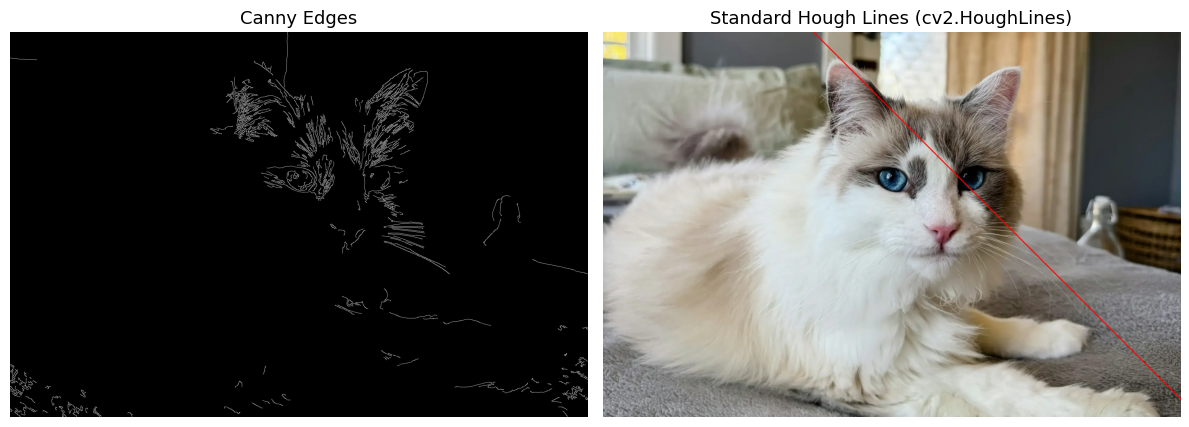

In [14]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 讀取影像與前處理（灰階 -> 高斯平滑 -> Canny 邊緣偵測）
img = cv2.imread('Ragdoll.png')
if img is None:
    raise FileNotFoundError("請確認影像路徑正確。")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (5, 5), 1.4)
edges = cv2.Canny(blur, 50, 150)

# 2. 執行標準霍夫直線轉換
# threshold 為累加器票數門檻，數值越高偵測到的直線越少
lines = cv2.HoughLines(edges, rho=1, theta=np.pi / 180, threshold=150)

# 3. 將極座標 (rho, theta) 轉換為笛卡兒座標端點並繪製無限長直線
result = img.copy()
line_len = max(img.shape[:2]) * 2  # 確保延伸長度足以貫穿整張影像

if lines is not None:
    for line in lines:
        rho, theta = line[0]
        a = np.cos(theta)
        b = np.sin(theta)
        x0 = a * rho
        y0 = b * rho
        x1 = int(x0 + line_len * (-b))
        y1 = int(y0 + line_len * (a))
        x2 = int(x0 - line_len * (-b))
        y2 = int(y0 - line_len * (a))
        cv2.line(result, (x1, y1), (x2, y2), (0, 0, 255), 2)

# 4. 顯示對比結果
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(edges, cmap='gray')
plt.title('Canny Edges', fontsize=13)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title('Standard Hough Lines (cv2.HoughLines)', fontsize=13)
plt.axis('off')

plt.tight_layout()
plt.show()

### cv2.HoughLinesP
機率霍夫直接輸出**有限線段的起點與終點座標 $(x_1, y_1, x_2, y_2)$**，能精準貼合物體或背景結構的實際長度，不會畫出貫穿整張圖的延伸線（此處以綠色繪製）。

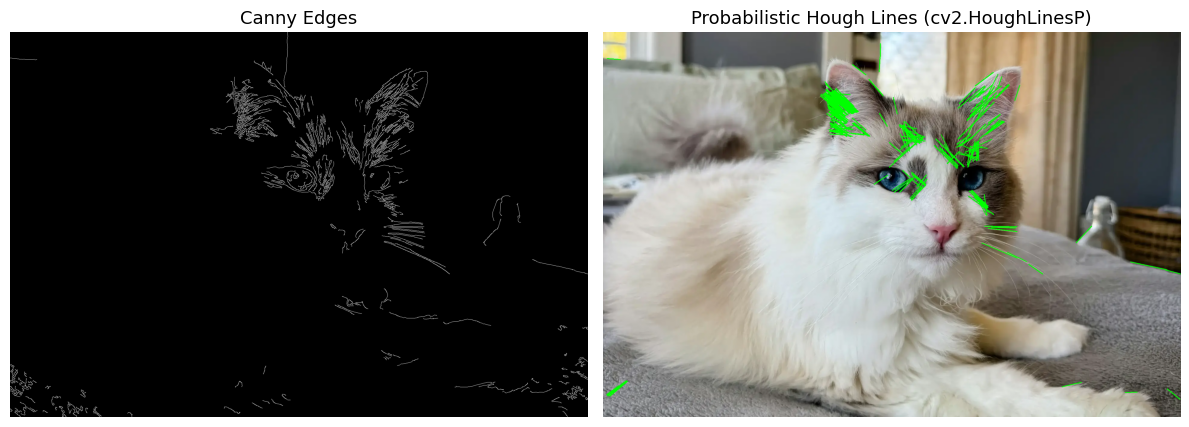

In [17]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 讀取影像與前處理（灰階 -> 高斯平滑 -> Canny 邊緣偵測）
img = cv2.imread('Ragdoll.png')
if img is None:
    raise FileNotFoundError("請確認影像路徑正確。")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (5, 5), 1.4)
edges = cv2.Canny(blur, 50, 150)

# 2. 執行機率霍夫直線轉換
lines = cv2.HoughLinesP(
    edges,
    rho=1,               # 距離解析度 (像素)
    theta=np.pi / 180,   # 角度解析度 (1 度)
    threshold=60,        # 累加器最少票數
    minLineLength=40,    # 線段最短長度，小於此值捨棄
    maxLineGap=10        # 同一條直線上允許的最大斷點間距
)

# 3. 直接依據回傳端點繪製有限線段（相容 (N, 1, 4) 與 (N, 4)）
result = img.copy()
if lines is not None:
  for x1, y1, x2, y2 in lines.reshape(-1, 4):
    cv2.line(result, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2)

# 4. 顯示對比結果
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(edges, cmap='gray')
plt.title('Canny Edges', fontsize=13)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title('Probabilistic Hough Lines (cv2.HoughLinesP)', fontsize=13)
plt.axis('off')

plt.tight_layout()
plt.show()

## 5.2 霍夫圓形偵測原理

圓形的數學方程式包含三個未知數（圓心 $a, b$ 與半徑 $r$）：

$$(x - a)^2 + (y - b)^2 = r^2$$

若直接在 3D 參數空間 $(a, b, r)$ 中暴力投票，記憶體與計算量將呈立方級暴增。為此，OpenCV 的 `cv2.HoughCircles` 採用霍夫梯度法（Hough Gradient Method）進行兩階段加速：

1. **圓心偵測**：利用邊緣像素的**梯度方向**（圓上任一點的梯度方向必定指向圓心），沿梯度法線方向在 2D 空間投票，找出高票數的候選圓心 $(a, b)$。
2. **半徑估算**：針對每個候選圓心，計算所有非零邊緣點到該圓心的距離直方圖，票數最高（支持度最大）的距離即為最佳半徑 $r$。

OpenCV 4.3+ 新增了 `cv2.HOUGH_GRADIENT_ALT` 模式，採用 Scharr 導數計算梯度，對小圓與高精度圓形偵測表現更佳。

---

### cv2.HoughCircles

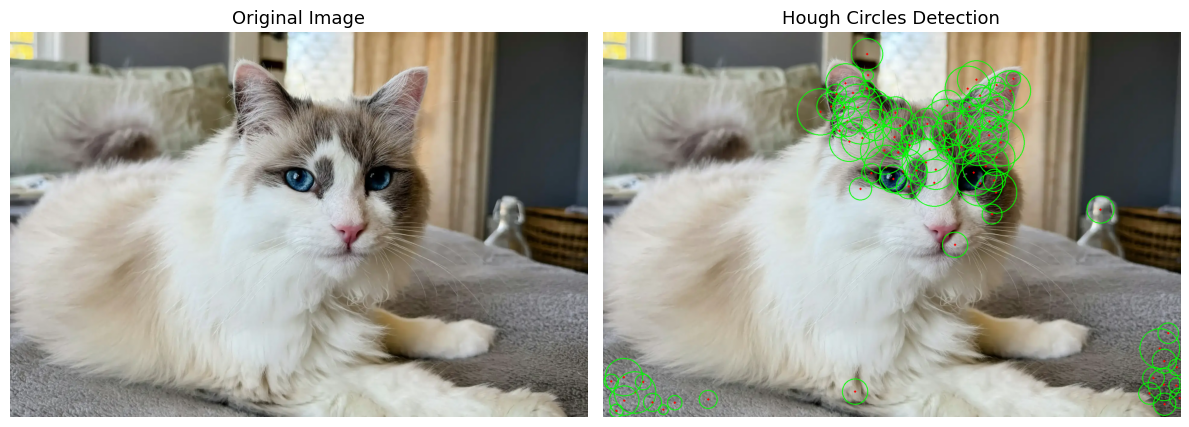

In [13]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 讀取影像並轉灰階、平滑降噪（注意：HoughCircles 內部已包含 Canny，不需手動先算）
img = cv2.imread('Ragdoll.png')
if img is None:
  raise FileNotFoundError("請確認影像路徑正確。")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blur = cv2.medianBlur(gray, 5)  # 中值濾波或高斯濾波皆可，減少雜訊誤判

# 2. 執行霍夫圓形轉換
circles = cv2.HoughCircles(
    blur,
    method=cv2.HOUGH_GRADIENT,
    dp=1.2,              # 累加器解析度與原圖比例 (1.0=同解析度, >1=降低解析度加快速度)
    minDist=40,          # 偵測到的圓心之間最小距離（避免同一個圓被重複畫出）
    param1=100,          # 內部 Canny 邊緣偵測的高閾值（低閾值自動設為其一半）
    param2=35,           # 圓心累加器投票閾值（越小越容易誤檢假圓，越大越嚴格）
    minRadius=15,        # 最小偵測半徑
    maxRadius=80         # 最大偵測半徑 (設為 0 表示不限制)
)

# 3. 繪製偵測到的圓形與圓心
result = img.copy()
if circles is not None:
    circles = np.uint16(np.around(circles))
    for x, y, r in circles[0, :]:
        cv2.circle(result, (x, y), r, (0, 255, 0), 2)    # 繪製外圓
        cv2.circle(result, (x, y), 2, (0, 0, 255), 3)    # 繪製圓心

# 4. 顯示結果
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original Image', fontsize=13)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title('Hough Circles Detection', fontsize=13)
plt.axis('off')

plt.tight_layout()
plt.show()

### cv2.HOUGH_GRADIENT_ALT





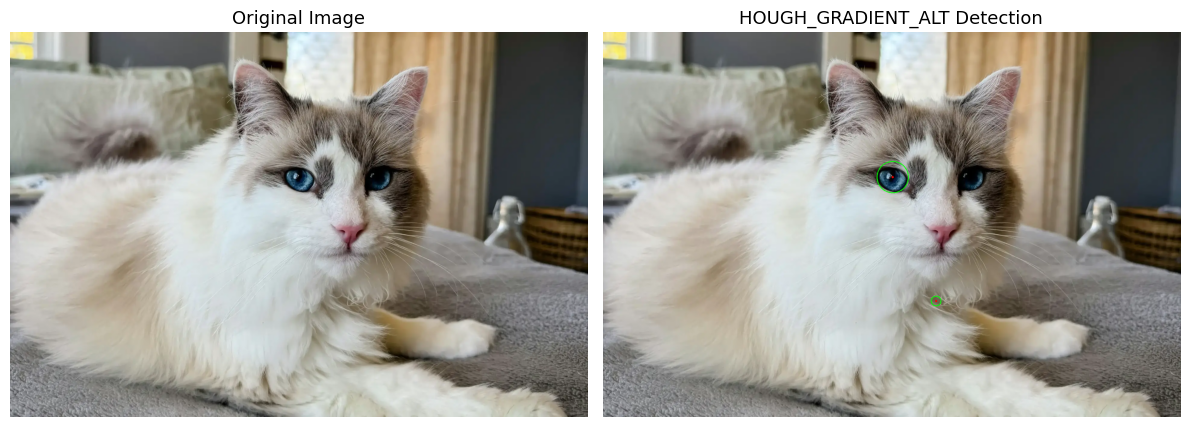

In [19]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 讀取影像並轉為灰階、輕微平滑降噪
img = cv2.imread('Ragdoll.png')
if img is None:
  raise FileNotFoundError("請確認影像路徑正確。")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (5, 5), 1.5)

# 2. 使用 HOUGH_GRADIENT_ALT 執行霍夫圓形偵測
circles = cv2.HoughCircles(
    blur,
    method=cv2.HOUGH_GRADIENT_ALT,
    dp=1.5,              # 建議從 1.5 開始微調
    minDist=30,          # 圓心之間最小距離
    param1=300,          # Scharr 梯度幅值較大，Canny 高閾值需設較高
    param2=0.85,         # 圓度門檻 (0~1)：0.85 代表要求相當接近正圓
    minRadius=10,        # 最小半徑
    maxRadius=100        # 最大半徑 (設為 0 表示不限制)
)

# 3. 繪製偵測結果（相容不同 OpenCV 版本的回傳維度）
result = img.copy()
if circles is not None:
    for x, y, r in np.round(circles.reshape(-1, 3)).astype(int):
        cv2.circle(result, (x, y), r, (0, 255, 0), 2)    # 綠色外圓
        cv2.circle(result, (x, y), 2, (0, 0, 255), 3)    # 紅色圓心

# 4. 顯示對比結果
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original Image', fontsize=13)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title('HOUGH_GRADIENT_ALT Detection', fontsize=13)
plt.axis('off')

plt.tight_layout()
plt.show()